# Tutorial 10: Segmentation using U-Net in PyTorch

## Block 1: Import libraries

In [1]:
import json
import time
import random
import shutil
import zipfile
import xml.etree.ElementTree as ET
from pathlib import Path
import yaml
import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from google.colab import files

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(42)
print('Device:', device)

Device: cuda


## Block 2: Prepare the dataset (synthetic images and masks)

Images: (100, 128, 128, 3) | Masks: (100, 128, 128)


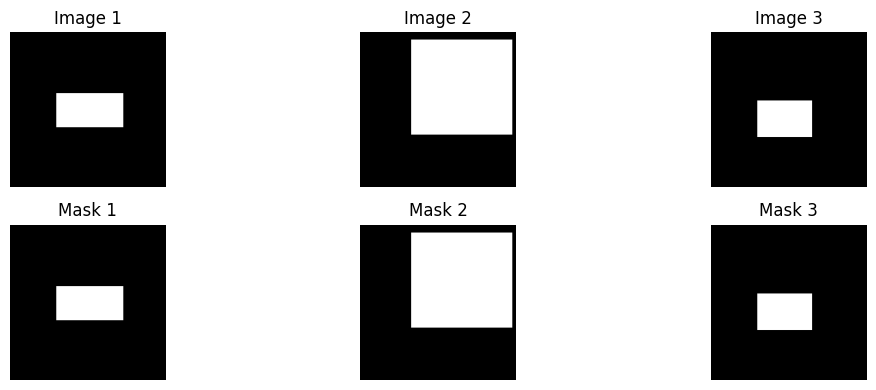

In [2]:
def create_sample_data(img_size=128, num_samples=100):
    images = []
    masks = []
    for _ in range(num_samples):
        img = np.zeros((img_size, img_size, 3), dtype=np.uint8)
        mask = np.zeros((img_size, img_size), dtype=np.uint8)
        # Add a random rectangle
        x1, y1, x2, y2 = np.random.randint(0, img_size // 2, 4)
        x2, y2 = x2 + img_size // 2, y2 + img_size // 2
        img = cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (255, 255, 255), -1)
        mask = cv2.rectangle(mask, (int(x1), int(y1)), (int(x2), int(y2)), 1, -1)
        images.append(img)
        masks.append(mask)
    return np.array(images) / 255.0, np.array(masks)  # Normalize to [0, 1]


# Generate synthetic data
images, masks = create_sample_data()
print('Images:', images.shape, '| Masks:', masks.shape)

plt.figure(figsize=(12, 4))
for i in range(3):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i])
    plt.title(f'Image {i + 1}')
    plt.axis('off')
    plt.subplot(2, 3, i + 4)
    plt.imshow(masks[i], cmap='gray')
    plt.title(f'Mask {i + 1}')
    plt.axis('off')
plt.tight_layout()
plt.show()

## Block 3: Define the U-Net model

In [3]:
def double_conv(in_ch, out_ch, batch_norm=False, dropout=0.0):
    # Two 3x3 convolutions with ReLU (optionally with batch normalization and dropout)
    layers = []
    for i in range(2):
        layers.append(nn.Conv2d(in_ch if i == 0 else out_ch, out_ch, 3, padding=1))
        if batch_norm:
            layers.append(nn.BatchNorm2d(out_ch))
        layers.append(nn.ReLU(inplace=True))
    if dropout:
        layers.append(nn.Dropout2d(dropout))
    return nn.Sequential(*layers)


class UNet(nn.Module):
    # filters=(64, 128, 256) is the tutorial's U-Net: 2 encoder levels, a bottleneck and 2 decoder levels
    def __init__(self, filters=(64, 128, 256), batch_norm=False, dropout=0.0):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.up = nn.Upsample(scale_factor=2, mode='nearest')  # same as Keras UpSampling2D

        # Encoder
        self.encoder = nn.ModuleList()
        in_ch = 3
        for f in filters[:-1]:
            self.encoder.append(double_conv(in_ch, f, batch_norm))
            in_ch = f

        # Bottleneck
        self.bottleneck = double_conv(in_ch, filters[-1], batch_norm, dropout)

        # Decoder: upsample, concatenate with the encoder output of the same size, two convolutions
        self.decoder = nn.ModuleList()
        in_ch = filters[-1]
        for f in reversed(filters[:-1]):
            self.decoder.append(double_conv(in_ch + f, f, batch_norm))
            in_ch = f

        self.out = nn.Conv2d(in_ch, 1, 1)

    def forward(self, x):
        skips = []
        for enc in self.encoder:
            x = enc(x)
            skips.append(x)
            x = self.pool(x)
        x = self.bottleneck(x)
        for dec, skip in zip(self.decoder, reversed(skips)):
            x = dec(torch.cat([self.up(x), skip], dim=1))
        # 1x1 convolution to one channel. The sigmoid is applied in the loss
        # (BCEWithLogitsLoss) and when predicting, which is more stable than a sigmoid layer.
        return self.out(x)


def summary(model, input_size):
    # Output shape and parameters of every convolution layer, like Keras' model.summary()
    rows, hooks = [], []

    def hook(module, inputs, output):
        rows.append((module.__class__.__name__, tuple(output.shape), sum(p.numel() for p in module.parameters())))

    for m in model.modules():
        if isinstance(m, (nn.Conv2d, nn.MaxPool2d, nn.Upsample)):
            hooks.append(m.register_forward_hook(hook))
    was_training = model.training
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, 3, input_size, input_size, device=next(model.parameters()).device))
    model.train(was_training)
    for h in hooks:
        h.remove()
    print(f"{'Layer':12} {'Output shape':>22} {'Params':>12}")
    for name, shape, params in rows:
        print(f"{name:12} {str(shape):>22} {params:12,}")
    print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")


# Build the model
model = UNet().to(device)
summary(model, 128)

Layer                  Output shape       Params
Conv2d            (1, 64, 128, 128)        1,792
Conv2d            (1, 64, 128, 128)       36,928
MaxPool2d           (1, 64, 64, 64)            0
Conv2d             (1, 128, 64, 64)       73,856
Conv2d             (1, 128, 64, 64)      147,584
MaxPool2d          (1, 128, 32, 32)            0
Conv2d             (1, 256, 32, 32)      295,168
Conv2d             (1, 256, 32, 32)      590,080
Upsample           (1, 256, 64, 64)            0
Conv2d             (1, 128, 64, 64)      442,496
Conv2d             (1, 128, 64, 64)      147,584
Upsample         (1, 128, 128, 128)            0
Conv2d            (1, 64, 128, 128)      110,656
Conv2d            (1, 64, 128, 128)       36,928
Conv2d             (1, 1, 128, 128)           65
Total parameters: 1,883,137


## Block 4: Train the model

In [4]:
def evaluate(model, x, y, batch_size=8):
    # Loss, pixel accuracy, IoU and Dice of the foreground (mask = 1) over a whole set
    model.eval()
    total_loss, correct, total, tp, fp, fn = 0.0, 0, 0, 0, 0, 0
    with torch.no_grad():
        for k in range(0, len(x), batch_size):
            xb, yb = x[k:k + batch_size].to(device), y[k:k + batch_size].to(device)
            logits = model(xb)
            total_loss += F.binary_cross_entropy_with_logits(logits, yb, reduction='sum').item()
            pred = (logits > 0).float()  # sigmoid(logit) > 0.5
            correct += (pred == yb).sum().item()
            total += yb.numel()
            tp += (pred * yb).sum().item()
            fp += (pred * (1 - yb)).sum().item()
            fn += ((1 - pred) * yb).sum().item()
    return {'loss': total_loss / total, 'accuracy': correct / total,
            'iou': tp / (tp + fp + fn) if tp + fp + fn else 1.0,
            'dice': 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 1.0}


def fit(model, train_x, train_y, val_x, val_y, epochs=20, lr=1e-4, batch_size=8, augment=False, print_every=1):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {k: [] for k in ('loss', 'accuracy', 'val_loss', 'val_accuracy', 'val_iou', 'val_dice')}
    start = time.time()
    for epoch in range(epochs):
        model.train()
        order = torch.randperm(len(train_x))
        total_loss, correct, total = 0.0, 0, 0
        for k in range(0, len(order), batch_size):
            idx = order[k:k + batch_size]
            xb, yb = train_x[idx].to(device), train_y[idx].to(device)
            if augment:  # random horizontal flip of the image and its mask
                flip = torch.rand(len(idx), device=device) < 0.5
                xb[flip] = xb[flip].flip(-1)
                yb[flip] = yb[flip].flip(-1)
            logits = model(xb)
            loss = F.binary_cross_entropy_with_logits(logits, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * yb.numel()
            correct += ((logits > 0).float() == yb).sum().item()
            total += yb.numel()
        val = evaluate(model, val_x, val_y, batch_size)
        history['loss'].append(total_loss / total)
        history['accuracy'].append(correct / total)
        for key in ('loss', 'accuracy', 'iou', 'dice'):
            history[f'val_{key}'].append(val[key])
        if epoch == 0 or (epoch + 1) % print_every == 0:
            print(f"Epoch {epoch + 1}/{epochs} - loss: {history['loss'][-1]:.4f} - accuracy: {history['accuracy'][-1]:.4f}"
                  f" - val_loss: {val['loss']:.4f} - val_accuracy: {val['accuracy']:.4f} - val_iou: {val['iou']:.4f}")
    history['time'] = time.time() - start
    return history


# Split data into training and validation sets
x_all = torch.tensor(images, dtype=torch.float32).permute(0, 3, 1, 2)  # (N, 3, 128, 128)
y_all = torch.tensor(masks, dtype=torch.float32).unsqueeze(1)          # (N, 1, 128, 128)
train_images, val_images = x_all[:80], x_all[80:]
train_masks, val_masks = y_all[:80], y_all[80:]

# Train the U-Net model
history = fit(model, train_images, train_masks, val_images, val_masks, epochs=20, lr=1e-4, batch_size=8)

Epoch 1/20 - loss: 0.6987 - accuracy: 0.2400 - val_loss: 0.6883 - val_accuracy: 0.2609 - val_iou: 0.2609
Epoch 2/20 - loss: 0.6684 - accuracy: 0.7977 - val_loss: 0.6097 - val_accuracy: 0.9937 - val_iou: 0.9761
Epoch 3/20 - loss: 0.3842 - accuracy: 0.9800 - val_loss: 0.0789 - val_accuracy: 0.9832 - val_iou: 0.9366
Epoch 4/20 - loss: 0.0409 - accuracy: 0.9889 - val_loss: 0.0493 - val_accuracy: 0.9865 - val_iou: 0.9503
Epoch 5/20 - loss: 0.0368 - accuracy: 0.9903 - val_loss: 0.0432 - val_accuracy: 0.9885 - val_iou: 0.9569
Epoch 6/20 - loss: 0.0273 - accuracy: 0.9911 - val_loss: 0.0254 - val_accuracy: 0.9908 - val_iou: 0.9658
Epoch 7/20 - loss: 0.0192 - accuracy: 0.9943 - val_loss: 0.0214 - val_accuracy: 0.9935 - val_iou: 0.9755
Epoch 8/20 - loss: 0.0171 - accuracy: 0.9950 - val_loss: 0.0186 - val_accuracy: 0.9945 - val_iou: 0.9790
Epoch 9/20 - loss: 0.0144 - accuracy: 0.9957 - val_loss: 0.0140 - val_accuracy: 0.9959 - val_iou: 0.9846
Epoch 10/20 - loss: 0.0116 - accuracy: 0.9968 - val_los

## Block 5: Evaluate the model

In [5]:
val = evaluate(model, val_images, val_masks)
print(f"Validation Loss: {val['loss']:.4f}, Validation Accuracy: {val['accuracy']:.4f}")
print(f"Validation IoU: {val['iou']:.4f}, Validation Dice: {val['dice']:.4f}")

Validation Loss: 0.0036, Validation Accuracy: 0.9985
Validation IoU: 0.9945, Validation Dice: 0.9972


## Block 6: Visualize predictions

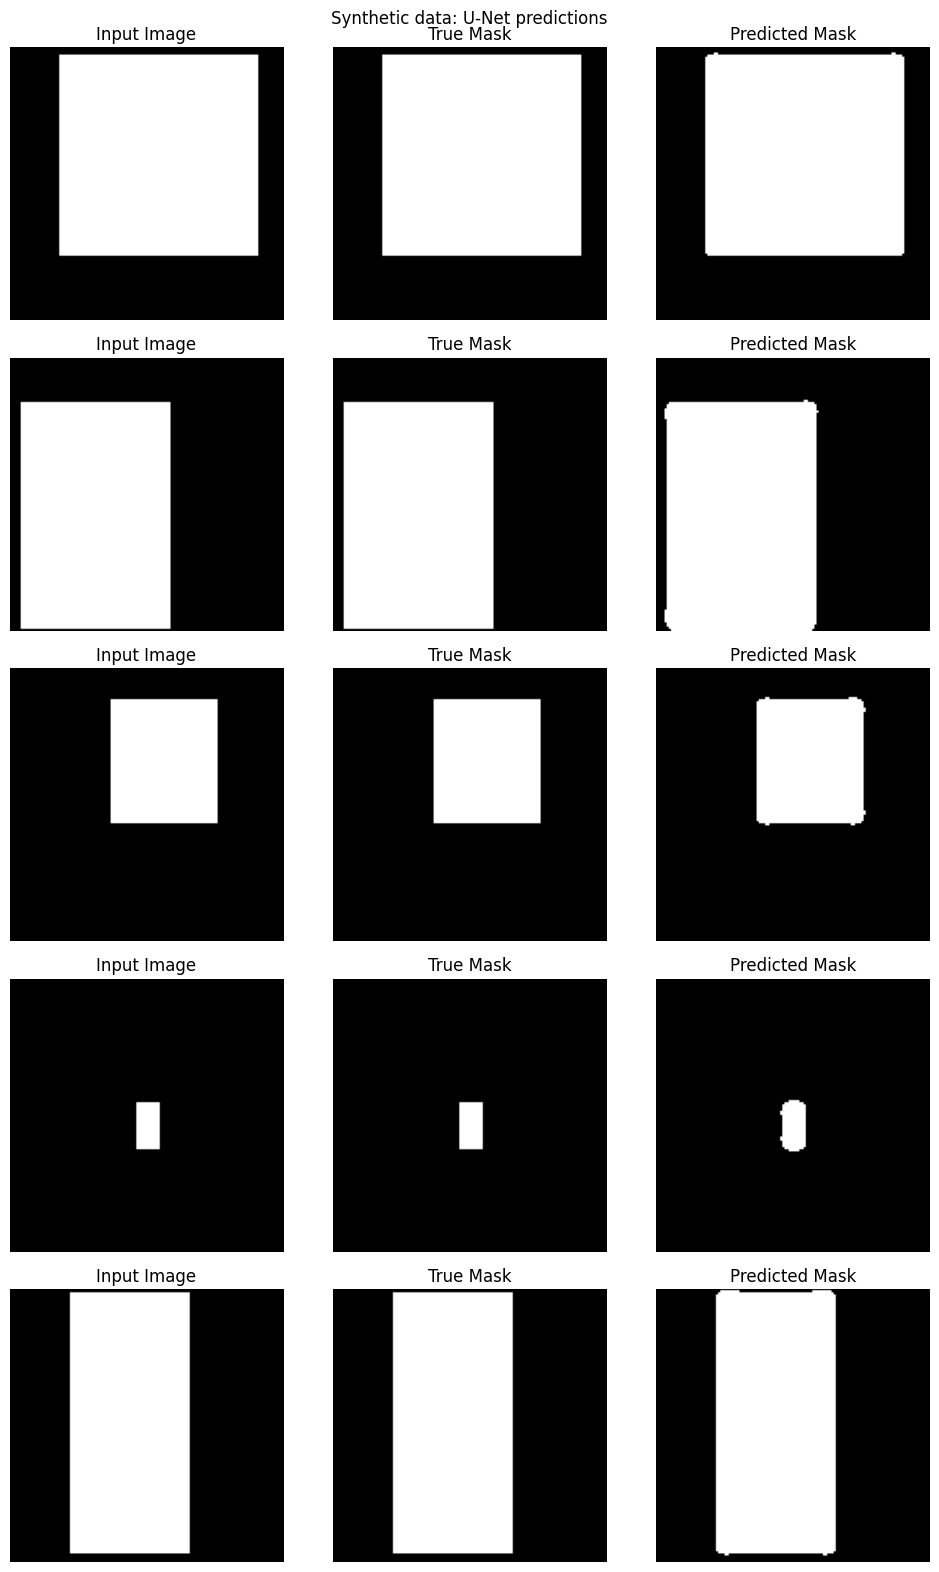

In [6]:
def predict(model, x, batch_size=8):
    model.eval()
    outputs = []
    with torch.no_grad():
        for k in range(0, len(x), batch_size):
            outputs.append(torch.sigmoid(model(x[k:k + batch_size].to(device))).cpu())
    return torch.cat(outputs)


def plot_samples(images, true_masks, pred_masks, indices, title=None):
    plt.figure(figsize=(10, 3.2 * len(indices)))
    for r, i in enumerate(indices):
        for c, (img, name) in enumerate([(images[i].permute(1, 2, 0), 'Input Image'),
                                         (true_masks[i, 0], 'True Mask'),
                                         ((pred_masks[i, 0] > 0.5).float(), 'Predicted Mask')]):
            plt.subplot(len(indices), 3, r * 3 + c + 1)
            plt.imshow(img, cmap=None if c == 0 else 'gray')
            plt.title(name)
            plt.axis('off')
    if title:
        plt.suptitle(title)
    plt.tight_layout()
    plt.show()


# Predict on the validation samples and show 5 examples
pred_masks = predict(model, val_images)
plot_samples(val_images, val_masks, pred_masks, range(5), 'Synthetic data: U-Net predictions')

## Block 7: Task 1 - Read the boxes drawn on the images

In [7]:
# Reads the boxes back from images that have labelled boxes drawn on them
# (e.g. Annotated_Images.zip): every class was drawn in its own exact colour with a name tag,
# so each tag is found by exact template matching and its rectangle is traced from the line pixels.
# The drawings are then painted out (inpainting) so the detectors are tested on clean pictures.
# Colours used when the boxes were drawn (RGB), one per class
CLASS_COLORS = {
    'trafficlight': (255, 193, 7),
    'stop': (220, 53, 69),
    'speedlimit': (0, 123, 255),
    'crosswalk': (40, 167, 69),
}


def draw_style(shape):
    h, w = shape[:2]
    return max(2, round(min(h, w) / 150)), max(0.4, min(h, w) / 600)


def tag_size(name, shape):
    _, fs = draw_style(shape)
    (tw, th), base = cv2.getTextSize(name, cv2.FONT_HERSHEY_SIMPLEX, fs, 1)
    return tw, th, base


def draw_box(canvas, name, x1, y1, x2, y2, color, outline=True, tag=True):
    # Same drawing routine that produced the annotated images
    t, fs = draw_style(canvas.shape)
    tw, th, base = tag_size(name, canvas.shape)
    if outline:
        cv2.rectangle(canvas, (x1, y1), (x2, y2), color, t)
    if tag:
        ty = max(y1, th + base + 4)
        cv2.rectangle(canvas, (x1, ty - th - base - 4), (x1 + tw + 6, ty), color, -1)
        cv2.putText(canvas, name, (x1 + 3, ty - base - 2), cv2.FONT_HERSHEY_SIMPLEX,
                    fs, (255, 255, 255), 1, cv2.LINE_AA)


def tag_template(name, color, shape):
    tw, th, base = tag_size(name, shape)
    th_tag = th + base + 4
    tmpl = np.zeros(shape, np.uint8)
    draw_box(tmpl, name, 0, th_tag, 1, th_tag + 1, color, outline=False)
    return (tmpl[:th_tag + 1, :tw + 7] == np.array(color, np.uint8)).all(-1).astype(np.float32), th_tag


def find_all_tags(img):
    # Locate every label tag by matching the exact rendered tag. Tags already found (and other
    # classes' drawings) are treated as wildcards, so a tag partly hidden under another is still found.
    h, w = img.shape[:2]
    masks = {n: (img == np.array(c, np.uint8)).all(-1) for n, c in CLASS_COLORS.items()}
    any_col = np.zeros((h, w), bool)
    for m in masks.values():
        any_col |= m
    found = []
    W = np.zeros((h, w), np.float32)  # wildcard pixels: covered by a tag found earlier
    while True:
        best = None
        for name, color in CLASS_COLORS.items():
            if not masks[name].any():
                continue
            F, th_tag = tag_template(name, color, img.shape)
            th_, tw_ = F.shape
            E = masks[name].astype(np.float32)
            wild = np.maximum(W, (any_col & ~masks[name]).astype(np.float32))
            P = lambda a: cv2.copyMakeBorder(a, 0, th_, 0, tw_, cv2.BORDER_CONSTANT, value=0)
            K = P((1 - wild))            # pixels inside the image that are not wildcards
            Ek = P(E * (1 - wild))
            agree = cv2.matchTemplate(Ek, F, cv2.TM_CCORR) + cv2.matchTemplate(K - Ek, 1 - F, cv2.TM_CCORR)
            known = cv2.matchTemplate(K, np.ones_like(F), cv2.TM_CCORR)
            ratio = np.where(known >= 0.25 * F.size, agree / np.maximum(known, 1), 0)
            y, x = np.unravel_index(np.argmax(ratio), ratio.shape)
            if ratio[y, x] >= 0.92 and (best is None or known[y, x] > best[0]):
                best = (known[y, x], name, int(x), int(y), th_tag, tw_, th_)
        if best is None:
            break
        _, name, x, y, th_tag, tw_, th_ = best
        found.append((name, x, y + th_tag))  # (class, x1, bottom row of the tag)
        W[y:y + th_, x:x + tw_] = 1
    return found


def run_end(line, start):
    # last index of the run of True values that begins at `start`
    i = start
    while i + 1 < len(line) and line[i + 1]:
        i += 1
    return i if line[start] else None


def best_box(mask, covered, free, name, color, shape, x1, y1_options, x2s, y2s, min_y2):
    # Smallest rectangle whose drawn outline is fully supported by the image
    h, w = shape[:2]
    best = None
    for y1 in y1_options:
        cands = sorted(((x2, y2) for x2 in set(x2s) for y2 in set(y2s)
                        if x2 > x1 + 2 and y2 > max(y1 + 2, min_y2)),
                       key=lambda b: (b[0] - x1) * (b[1] - y1))
        for x2, y2 in cands:
            if best is not None and (x2 - x1) * (y2 - y1) >= best[0]:
                break
            canvas = np.zeros(shape, np.uint8)
            draw_box(canvas, name, x1, y1, x2, y2, color, tag=False)
            out = (canvas == np.array(color, np.uint8)).all(-1)
            n = np.count_nonzero(out)
            if n == 0:
                continue
            if np.count_nonzero(out & mask & free) < 0.3 * n:   # a good part must be visibly drawn in this colour
                continue
            if np.count_nonzero(out & covered) >= 0.95 * n:
                best = ((x2 - x1) * (y2 - y1), (x1, y1, min(x2, w - 1), min(y2, h - 1)))
                break
    return best[1] if best else None


def edge_candidates(covered, mask, other_tags, x1, y1, t, shape):
    h, w = shape[:2]
    k = max(4, 2 * t)
    r0, r1 = min(h - 1, y1 + t + 1), min(h, y1 + t + 1 + k)
    c0, c1 = min(w - 1, x1 + t + 1), min(w, x1 + t + 1 + k)
    vert = [covered[r0:r1, c].all() for c in range(w)]
    horz = [covered[r, c0:c1].all() for r in range(h)]
    x2s = [c for c in range(x1 + 3, w) if vert[c] and (c + 1 >= w or not vert[c + 1])]
    y2s = [r for r in range(y1 + 3, h) if horz[r] and (r + 1 >= h or not horz[r + 1])]
    x2s = [c - d for c in x2s for d in range(t + 1)] + [w + 50]
    y2s = [r - d for r in y2s for d in range(t + 1)] + [h + 50]
    for m in (mask, covered):  # where the top edge and the left edge stop
        e = run_end(m[min(h - 1, y1), :], x1) if 0 <= y1 < h else None
        if e is not None:
            x2s += [e - d for d in range(t + 1)]
        e = run_end(m[:, x1], max(0, y1))
        if e is not None:
            y2s += [e - d for d in range(t + 1)]
    # edges hidden under other tags
    ys, xs = np.nonzero(other_tags[:, x1:x1 + 1])
    y2s += [int(y) for y in ys if y > y1 + 2]
    if 0 <= y1 < h:
        xs = np.nonzero(other_tags[y1])[0]
        x2s += [int(x) for x in xs if x > x1 + 2]
    return x2s, y2s


def fit_from_tag(img, mask, covered, free, other_tags, name, color, x1, ty, own_tag):
    t, _ = draw_style(img.shape)
    tw, th, base = tag_size(name, img.shape)
    th_tag = th + base + 4
    y1_options = [ty] if ty > th_tag else list(range(0, th_tag + 1))
    best = None
    for y1 in y1_options:
        x2s, y2s = edge_candidates(covered | own_tag, mask, other_tags, x1, y1, t, img.shape)
        box = best_box(mask, covered | own_tag, free, name, color, img.shape,
                       x1, [y1], x2s, y2s, ty + t)
        if box and (best is None or (box[2] - box[0]) * (box[3] - box[1]) < best[0]):
            best = ((box[2] - box[0]) * (box[3] - box[1]), box)
    return best[1] if best else None


def fit_untagged(img, comp, covered, free, other_tags, name, color):
    # Box whose tag is hidden under another tag: start from the lowest visible edge
    h, w = img.shape[:2]
    t, _ = draw_style(img.shape)
    ys, xs = np.nonzero(comp)
    y_bot = ys.max()
    row = xs[ys == y_bot]
    x1, x2 = int(row.min()), int(row.max())
    y2 = int(min(y_bot, h - 1) - t // 2) if y_bot < h - 1 else h + 50
    return best_box(comp, covered, free, name, color, img.shape, x1,
                    range(max(0, int(ys.min()) - 2 * t), y2 - 2), [x2, x2 + 1, x2 - 1], [y2], 0)


def refine(box, mask, covered, tags_area, name, color, shape, move_x1=False, move_y1=False):
    # Nudge the box edges by a pixel or two to best match the drawn line pixels
    h, w = shape[:2]
    t, _ = draw_style(shape)
    x1, y1, x2, y2 = box
    r0, r1 = max(0, y1 - 3 * t), min(h, y2 + 3 * t + 1)
    c0, c1 = max(0, x1 - 3 * t), min(w, x2 + 3 * t + 1)
    target = mask[r0:r1, c0:c1] & ~tags_area[r0:r1, c0:c1]
    cov = covered[r0:r1, c0:c1]
    R = range(-t, t + 1)
    best = None
    for a in (R if move_x1 else [0]):
        for b in (R if move_y1 else [0]):
            for c in R:
                for d in R:
                    bx = (x1 + a, y1 + b, x2 + c, y2 + d)
                    if bx[2] <= bx[0] + 2 or bx[3] <= bx[1] + 2:
                        continue
                    canvas = np.zeros(shape, np.uint8)
                    draw_box(canvas, name, *bx, color, tag=False)
                    out = (canvas == np.array(color, np.uint8)).all(-1)[r0:r1, c0:c1]
                    score = (np.count_nonzero(out & target) - 3 * np.count_nonzero(out & ~cov)
                             - np.count_nonzero(target & ~out))
                    if best is None or score > best[0]:
                        best = (score, bx)
    x1, y1, x2, y2 = best[1]
    return (max(0, x1), max(0, y1), min(w - 1, x2), min(h - 1, y2))


def recover_boxes(img):
    # img: RGB image with boxes drawn on it -> list of (class name, (xmin, ymin, xmax, ymax))
    h, w = img.shape[:2]
    masks = {n: (img == np.array(c, np.uint8)).all(-1) for n, c in CLASS_COLORS.items()}
    tags = find_all_tags(img)
    all_tags = np.zeros((h, w), bool)
    regions = []
    for name, x1, ty in tags:
        tw, th, base = tag_size(name, img.shape)
        r = np.zeros((h, w), bool)
        r[max(0, ty - th - base - 4):ty + 1, x1:x1 + tw + 7] = True
        regions.append(r)
        all_tags |= r
    objects = []
    explained = all_tags.copy()
    for (name, x1, ty), own in zip(tags, regions):
        color = CLASS_COLORS[name]
        other = all_tags & ~own
        for n2, m2 in masks.items():
            if n2 != name:
                other |= m2
        box = fit_from_tag(img, masks[name], masks[name] | other, ~other, all_tags & ~own,
                           name, color, x1, ty, own)
        if box:
            tw, th, base = tag_size(name, img.shape)
            box = refine(box, masks[name], masks[name] | other | own, all_tags, name, color, img.shape,
                         move_y1=ty <= th + base + 4)
            objects.append((name, box))
            canvas = np.zeros(img.shape, np.uint8)
            draw_box(canvas, name, *box, color, tag=False)
            explained |= (canvas == np.array(color, np.uint8)).all(-1)
    # boxes whose tag was hidden: colour pixels that no box explains yet
    explained = cv2.dilate(explained.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool)
    for name, color in CLASS_COLORS.items():
        left = masks[name] & ~explained
        n, labels, stats, _ = cv2.connectedComponentsWithStats(left.astype(np.uint8), connectivity=8)
        for i in range(1, n):
            if stats[i, cv2.CC_STAT_AREA] < 40:
                continue
            other = all_tags.copy()
            for n2, m2 in masks.items():
                if n2 != name:
                    other |= m2
            box = fit_untagged(img, labels == i, masks[name] | other | explained, ~other, all_tags, name, color)
            if box:
                box = refine(box, masks[name], masks[name] | other | explained, all_tags, name, color,
                             img.shape, move_x1=True, move_y1=True)
                objects.append((name, box))
    return objects


def clean_image(img, objects):
    # Paint over the drawn boxes and tags so the detectors see the original picture
    h, w = img.shape[:2]
    any_col = np.zeros((h, w), bool)
    for c in CLASS_COLORS.values():
        any_col |= (img == np.array(c, np.uint8)).all(-1)
    footprint = np.zeros((h, w), np.uint8)
    for name, box in objects:
        canvas = np.zeros(img.shape, np.uint8)
        draw_box(canvas, name, *box, CLASS_COLORS[name])
        footprint |= canvas.any(-1).astype(np.uint8)
    footprint = cv2.dilate(footprint | any_col.astype(np.uint8), np.ones((3, 3), np.uint8))
    return cv2.inpaint(img, footprint, 3, cv2.INPAINT_TELEA)

## Block 8: Task 1 - Uploading the labelled images

In [8]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
MAX_IMAGES = 150   # how many labelled images to use (None = all)
SEED = 42          # same seed = same images every run


def open_image(path):
    # exif_transpose rotates phone photos the same way labelling tools display them
    return ImageOps.exif_transpose(Image.open(path)).convert('RGB')


def read_yolo_names(root):
    # Class names from classes.txt / obj.names / data.yaml (Roboflow, LabelImg, makesense)
    for txt in list(root.rglob('classes.txt')) + list(root.rglob('*.names')):
        names = [line.strip() for line in open(txt) if line.strip()]
        if names:
            return names
    for yml in list(root.rglob('data.yaml')) + list(root.rglob('*.yaml')):
        try:
            names = yaml.safe_load(open(yml)).get('names')
        except Exception:
            continue
        if isinstance(names, dict):
            names = [names[k] for k in sorted(names)]
        if names:
            return [str(n) for n in names]
    return []


def pick(paths):
    # random but repeatable subset
    paths = sorted(paths)
    random.Random(SEED).shuffle(paths)
    return paths


def load_labelled_zip(zip_path, extract_dir):
    shutil.rmtree(extract_dir, ignore_errors=True)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(extract_dir)
    root = Path(extract_dir)

    def usable(p):
        return '__MACOSX' not in p.parts and not p.name.startswith('.')

    images = {p.stem: p for p in root.rglob('*') if p.suffix.lower() in IMAGE_EXTS and usable(p)}
    xml_files = [p for p in root.rglob('*.xml') if usable(p)]
    txt_files = [p for p in root.rglob('*.txt') if usable(p) and p.name not in ('classes.txt', 'README.txt')]
    samples, skipped = [], 0
    enough = lambda: MAX_IMAGES is not None and len(samples) >= MAX_IMAGES

    if xml_files:
        label_format = 'Pascal VOC (.xml)'
        for xml_path in pick(xml_files):
            if enough():
                break
            ann = ET.parse(xml_path).getroot()
            img_path = images.get(xml_path.stem) or images.get(Path(ann.findtext('filename', '')).stem)
            if img_path is None:
                skipped += 1
                continue
            width, height = open_image(img_path).size
            xml_w = float(ann.findtext('size/width') or 0) or width
            xml_h = float(ann.findtext('size/height') or 0) or height
            sx, sy = width / xml_w, height / xml_h  # in case the image was resized after labelling
            objects = []
            for obj in ann.iter('object'):
                bb = obj.find('bndbox')
                x1, y1, x2, y2 = (float(bb.findtext(k)) for k in ('xmin', 'ymin', 'xmax', 'ymax'))
                box = [max(0, x1 * sx), max(0, y1 * sy), min(width, x2 * sx), min(height, y2 * sy)]
                if box[2] - box[0] > 1 and box[3] - box[1] > 1:
                    objects.append((obj.findtext('name').strip(), box))
            samples.append((img_path, objects))
    elif txt_files:
        label_format = 'YOLO (.txt)'
        names = read_yolo_names(root)
        for txt_path in pick(txt_files):
            if enough():
                break
            img_path = images.get(txt_path.stem)
            if img_path is None:
                skipped += 1
                continue
            width, height = open_image(img_path).size
            objects = []
            for line in open(txt_path):
                values = line.split()
                if len(values) < 5:
                    continue
                cls = int(float(values[0]))
                xc, yc, bw, bh = (float(v) for v in values[1:5])
                box = [max(0, (xc - bw / 2) * width), max(0, (yc - bh / 2) * height),
                       min(width, (xc + bw / 2) * width), min(height, (yc + bh / 2) * height)]
                if box[2] - box[0] > 1 and box[3] - box[1] > 1:
                    name = names[cls] if cls < len(names) else f'class_{cls}'
                    objects.append((name.strip(), box))
            samples.append((img_path, objects))
    elif images:
        # No label files: read the boxes from the colours drawn on the images
        label_format = 'boxes drawn on the images (read from their colours)'
        clean_dir = root / '_clean'
        clean_dir.mkdir(exist_ok=True)
        todo = pick(list(images.values()))
        print(f'Reading the drawn boxes from {len(todo)} images...')
        for k, img_path in enumerate(todo):
            if enough():
                break
            img = np.array(open_image(img_path))
            objects = recover_boxes(img)
            if not objects:
                skipped += 1
                continue
            clean_path = clean_dir / (img_path.stem + '.png')
            Image.fromarray(clean_image(img, objects)).save(clean_path)
            samples.append((clean_path, [(name, [float(v) for v in box]) for name, box in objects]))
            if (k + 1) % 25 == 0:
                print(f'  {k + 1} images done')
    else:
        raise ValueError('No images or label files found in the zip.')

    if not samples:
        raise ValueError('No labelled images found. Use a zip with images + .xml/.txt label files, or '
                         'images with the boxes drawn on them.')

    print('Label format:', label_format)
    print('Labelled images used:', len(samples))
    if skipped:
        print('Images skipped (no labels found):', skipped)
    counts = {}
    for _, objects in samples:
        for name, _ in objects:
            counts[name] = counts.get(name, 0) + 1
    for name, n in sorted(counts.items()):
        print(f'  {name}: {n} objects')
    return samples


def find_coco_polygons(root):
    # A COCO .json with polygon labels (makesense.ai "COCO JSON" or Roboflow "COCO Segmentation")
    for path in root.rglob('*.json'):
        if '__MACOSX' in path.parts:
            continue
        try:
            data = json.load(open(path))
        except Exception:
            continue
        if isinstance(data, dict) and 'images' in data and 'annotations' in data and any(
                isinstance(a.get('segmentation'), list) and a['segmentation'] for a in data['annotations']):
            return data
    return None


def polygon_samples(data, root):
    files_by_name = {p.name: p for p in root.rglob('*') if p.suffix.lower() in IMAGE_EXTS and '__MACOSX' not in p.parts}
    files_by_stem = {p.stem: p for p in files_by_name.values()}
    anns = {}
    for a in data['annotations']:
        anns.setdefault(a['image_id'], []).append(a)
    out = []
    for info in data['images']:
        name = Path(info['file_name']).name
        img_path = files_by_name.get(name) or files_by_stem.get(Path(name).stem)
        if img_path is None or info['id'] not in anns:
            continue
        w, h = open_image(img_path).size
        sx, sy = w / info.get('width', w), h / info.get('height', h)
        polygons = []
        for a in anns[info['id']]:
            if isinstance(a.get('segmentation'), list):
                for poly in a['segmentation']:
                    pts = np.array(poly, dtype=np.float32).reshape(-1, 2) * [sx, sy]
                    if len(pts) >= 3:
                        polygons.append(pts)
        out.append((img_path, polygons))
    return out


# Upload the labelled zip: the same road sign zip as Tutorials 8 and 9 (boxes), or images with polygon labels
uploaded = files.upload()
zip_name = next(name for name in uploaded if name.lower().endswith('.zip'))
extract_dir = '/content/seg_data'
shutil.rmtree(extract_dir, ignore_errors=True)
with zipfile.ZipFile(zip_name) as z:
    z.extractall(extract_dir)

coco = find_coco_polygons(Path(extract_dir))
if coco is not None:
    label_source = 'polygons'
    seg_samples = polygon_samples(coco, Path(extract_dir))
    print('Label format: COCO polygons |', len(seg_samples), 'labelled images')
else:
    label_source = 'boxes'
    seg_samples = load_labelled_zip(zip_name, extract_dir)

# Same 80/20 split as Tutorials 8 and 9
random.Random(42).shuffle(seg_samples)
split = int(0.8 * len(seg_samples))
train_samples, val_samples = seg_samples[:split], seg_samples[split:]
print('Training images:', len(train_samples), '| Validation images:', len(val_samples))

Saving Annotated Images.zip to Annotated Images.zip
Reading the drawn boxes from 150 images...
  25 images done
  50 images done
  75 images done
  100 images done
  125 images done
  150 images done
Label format: boxes drawn on the images (read from their colours)
Labelled images used: 149
Images skipped (no labels found): 1
  crosswalk: 34 objects
  speedlimit: 123 objects
  stop: 17 objects
  trafficlight: 19 objects
Training images: 119 | Validation images: 30


## Block 9: Task 1 - Create the segmentation masks

Masks created in 9.0 s
Objects: 193 | box: 80, grabcut: 113
Training set: (119, 3, 256, 256) (119, 1, 256, 256) | Validation set: (30, 3, 256, 256)
Sign pixels in the validation masks: 2.6% (a model that predicts "no sign" everywhere would already get 97.4% pixel accuracy)


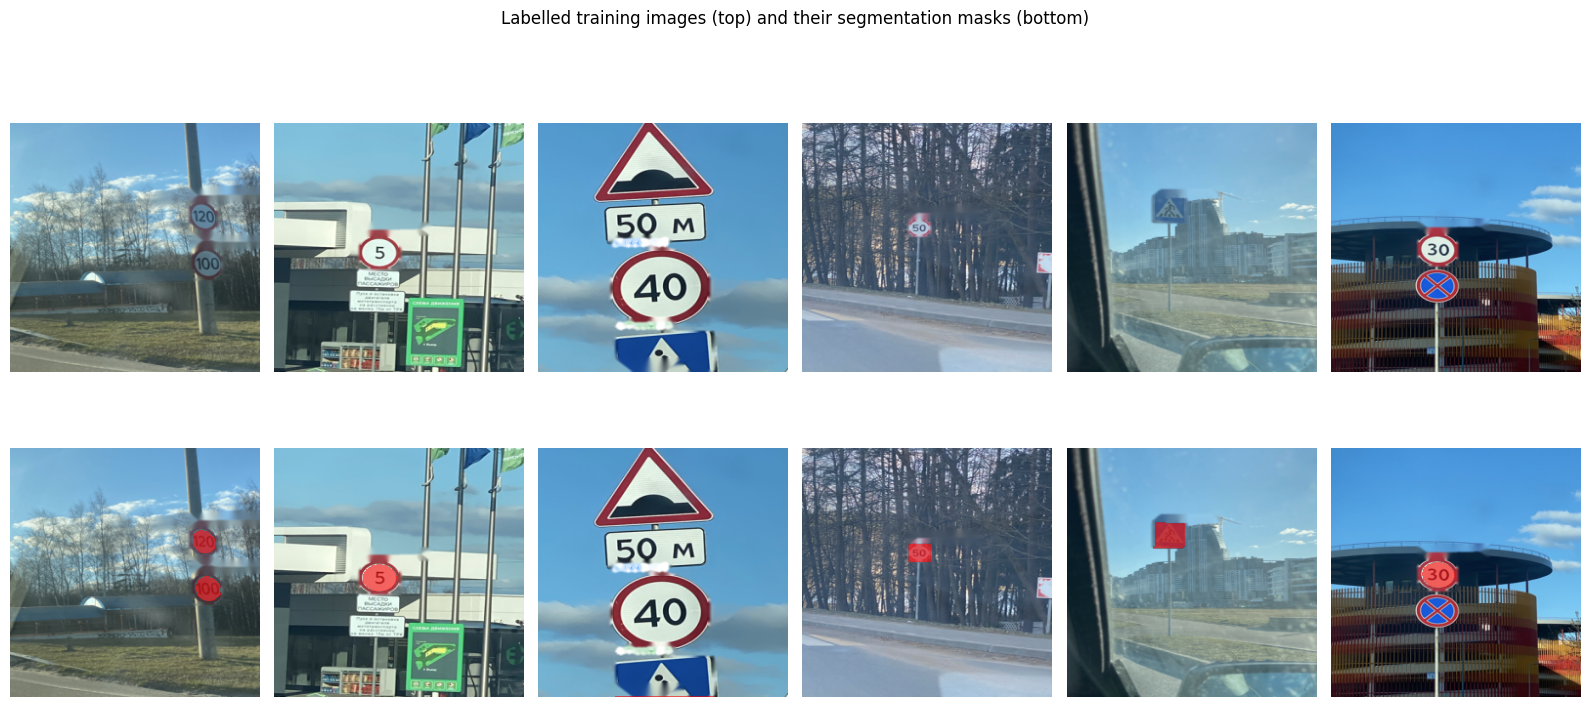

In [9]:
IMG_SIZE = 256  # images and masks are resized to 256x256 (the road signs are too small at 128x128)


def grabcut_object(img_bgr, box, iterations=5):
    # GrabCut separates the sign from its background inside the labelled box. The area outside the
    # box is used as known background, so the box is cropped with a margin around it.
    H, W = img_bgr.shape[:2]
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    x1, y1, x2, y2 = max(0, x1), max(0, y1), min(W, x2), min(H, y2)
    bw, bh = x2 - x1, y2 - y1
    full_box = np.zeros((H, W), bool)
    full_box[y1:y2, x1:x2] = True
    if bw < 10 or bh < 10:
        return full_box, 'box'  # too small for GrabCut
    m = max(bw, bh) // 2
    cx1, cy1, cx2, cy2 = max(0, x1 - m), max(0, y1 - m), min(W, x2 + m), min(H, y2 + m)
    crop = np.ascontiguousarray(img_bgr[cy1:cy2, cx1:cx2])
    rx, ry = x1 - cx1, y1 - cy1
    if rx == 0 and ry == 0 and rx + bw == crop.shape[1] and ry + bh == crop.shape[0]:
        return full_box, 'box'  # the box fills the image, so there is no background to learn from
    gc = np.zeros(crop.shape[:2], np.uint8)
    bgd, fgd = np.zeros((1, 65), np.float64), np.zeros((1, 65), np.float64)
    try:
        cv2.grabCut(crop, gc, (rx, ry, bw, bh), bgd, fgd, iterations, cv2.GC_INIT_WITH_RECT)
    except cv2.error:
        return full_box, 'box'
    obj = ((gc == cv2.GC_FGD) | (gc == cv2.GC_PR_FGD)).astype(np.uint8)
    obj = cv2.morphologyEx(obj, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    obj = cv2.morphologyEx(obj, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    # keep the largest part and fill its holes (e.g. the numbers inside a speed limit sign)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(obj)
    if n > 1:
        obj = (lab == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])).astype(np.uint8)
    contours, _ = cv2.findContours(obj, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    obj = np.zeros_like(obj)
    cv2.drawContours(obj, contours, -1, 1, -1)
    if obj[ry:ry + bh, rx:rx + bw].sum() < 0.25 * bw * bh:
        return full_box, 'box'  # GrabCut lost the sign, keep the whole box
    out = np.zeros((H, W), bool)
    out[cy1:cy2, cx1:cx2] = obj.astype(bool)
    return out & full_box, 'grabcut'


def make_mask(img_path, labels):
    img = np.array(open_image(img_path))
    mask = np.zeros(img.shape[:2], np.uint8)
    methods = []
    if label_source == 'polygons':
        for pts in labels:
            cv2.fillPoly(mask, [np.round(pts).astype(np.int32)], 1)
        methods = ['polygon'] * len(labels)
    else:
        bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
        for _, box in labels:
            obj, how = grabcut_object(bgr, box)
            mask[obj] = 1
            methods.append(how)
    return img, mask, methods


def build_set(samples):
    xs, ys, methods = [], [], []
    for img_path, labels in samples:
        img, mask, how = make_mask(img_path, labels)
        xs.append(cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA))
        ys.append(cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST))
        methods += how
    x = torch.tensor(np.stack(xs), dtype=torch.float32).permute(0, 3, 1, 2) / 255
    y = torch.tensor(np.stack(ys), dtype=torch.float32).unsqueeze(1)
    return x, y, methods


start = time.time()
train_x, train_y, m_train = build_set(train_samples)
val_x, val_y, m_val = build_set(val_samples)
methods = m_train + m_val
print(f'Masks created in {time.time() - start:.1f} s')
print('Objects:', len(methods), '|', ', '.join(f'{k}: {methods.count(k)}' for k in sorted(set(methods))))
print('Training set:', tuple(train_x.shape), tuple(train_y.shape), '| Validation set:', tuple(val_x.shape))
fg = val_y.mean().item()
print(f'Sign pixels in the validation masks: {fg * 100:.1f}% '
      f'(a model that predicts "no sign" everywhere would already get {(1 - fg) * 100:.1f}% pixel accuracy)')

plt.figure(figsize=(16, 8))
for k in range(6):
    plt.subplot(2, 6, k + 1)
    plt.imshow(train_x[k].permute(1, 2, 0))
    plt.axis('off')
    plt.subplot(2, 6, k + 7)
    plt.imshow(train_x[k].permute(1, 2, 0))
    plt.imshow(np.ma.masked_where(train_y[k, 0].numpy() == 0, train_y[k, 0].numpy()), cmap='autumn', alpha=0.6)
    plt.axis('off')
plt.suptitle('Labelled training images (top) and their segmentation masks (bottom)')
plt.tight_layout()
plt.show()

## Block 10: Task 2 - Train the tutorial's U-Net on the labelled data and change the layers

In [10]:
EPOCHS = 40
seg_results, seg_histories, seg_models = {}, {}, {}


def run(name, build, lr=1e-4, epochs=EPOCHS):
    set_seed(42)  # same starting weights and batches for a fair comparison
    model = build().to(device)
    print(f"\nTraining: {name} ({sum(p.numel() for p in model.parameters()):,} parameters, lr={lr})")
    h = fit(model, train_x, train_y, val_x, val_y, epochs=epochs, lr=lr, augment=True, print_every=10)
    seg_results[name] = {'params': sum(p.numel() for p in model.parameters()), 'lr': lr,
                         'accuracy': h['val_accuracy'][-1], 'iou': h['val_iou'][-1],
                         'dice': h['val_dice'][-1], 'best_iou': max(h['val_iou']), 'time': h['time']}
    seg_histories[name] = h
    seg_models[name] = model
    return model


variants = {
    'U-Net (tutorial) 64-128-256': lambda: UNet((64, 128, 256)),
    'Smaller 32-64-128': lambda: UNet((32, 64, 128)),
    'Deeper 64-128-256-512': lambda: UNet((64, 128, 256, 512)),
    'Deeper + BatchNorm + Dropout': lambda: UNet((64, 128, 256, 512), batch_norm=True, dropout=0.3),
}
for name, build in variants.items():
    run(name, build)

print(f"\n{'Model':30} {'Parameters':>11} {'Accuracy':>9} {'IoU':>7} {'Dice':>7} {'Best IoU':>9} {'Time (s)':>9}")
for name in variants:
    r = seg_results[name]
    print(f"{name:30} {r['params']:11,} {r['accuracy']:9.4f} {r['iou']:7.4f} {r['dice']:7.4f} {r['best_iou']:9.4f} {r['time']:9.1f}")
print('(validation set, after the last epoch; Best IoU = highest validation IoU in any epoch)')


Training: U-Net (tutorial) 64-128-256 (1,883,137 parameters, lr=0.0001)
Epoch 1/40 - loss: 0.6868 - accuracy: 0.4599 - val_loss: 0.6004 - val_accuracy: 0.9743 - val_iou: 0.0000
Epoch 10/40 - loss: 0.1297 - accuracy: 0.9689 - val_loss: 0.1124 - val_accuracy: 0.9744 - val_iou: 0.0000
Epoch 20/40 - loss: 0.0944 - accuracy: 0.9697 - val_loss: 0.0708 - val_accuracy: 0.9744 - val_iou: 0.0000
Epoch 30/40 - loss: 0.0855 - accuracy: 0.9691 - val_loss: 0.0671 - val_accuracy: 0.9742 - val_iou: 0.1727
Epoch 40/40 - loss: 0.0712 - accuracy: 0.9759 - val_loss: 0.0604 - val_accuracy: 0.9786 - val_iou: 0.3548

Training: Smaller 32-64-128 (471,553 parameters, lr=0.0001)
Epoch 1/40 - loss: 0.7249 - accuracy: 0.0311 - val_loss: 0.7125 - val_accuracy: 0.0256 - val_iou: 0.0256
Epoch 10/40 - loss: 0.1453 - accuracy: 0.9689 - val_loss: 0.1352 - val_accuracy: 0.9744 - val_iou: 0.0000
Epoch 20/40 - loss: 0.1246 - accuracy: 0.9689 - val_loss: 0.1111 - val_accuracy: 0.9744 - val_iou: 0.0000
Epoch 30/40 - loss: 

## Block 11: Task 2 - Visualize the results of the different layers

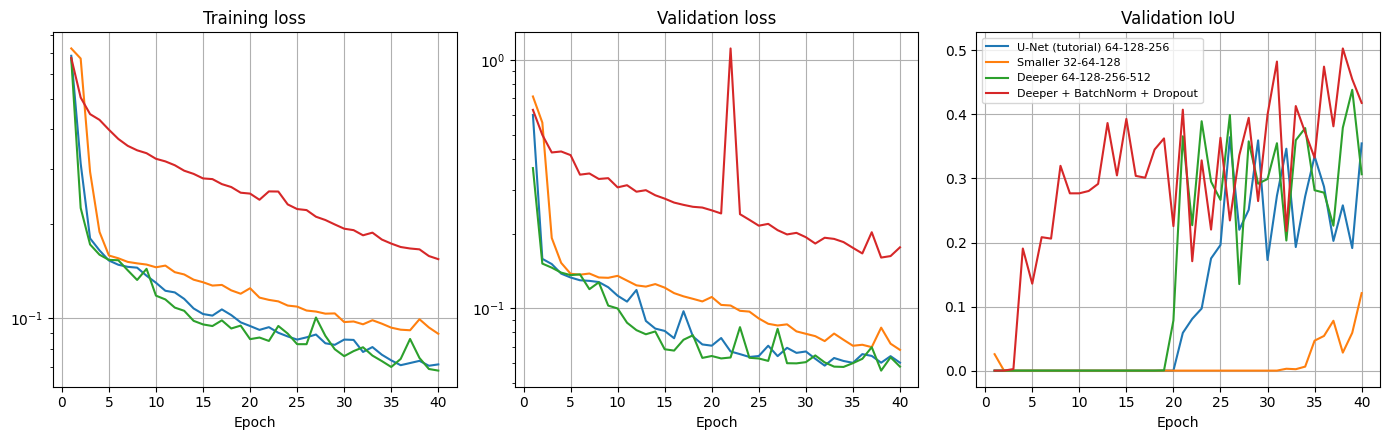

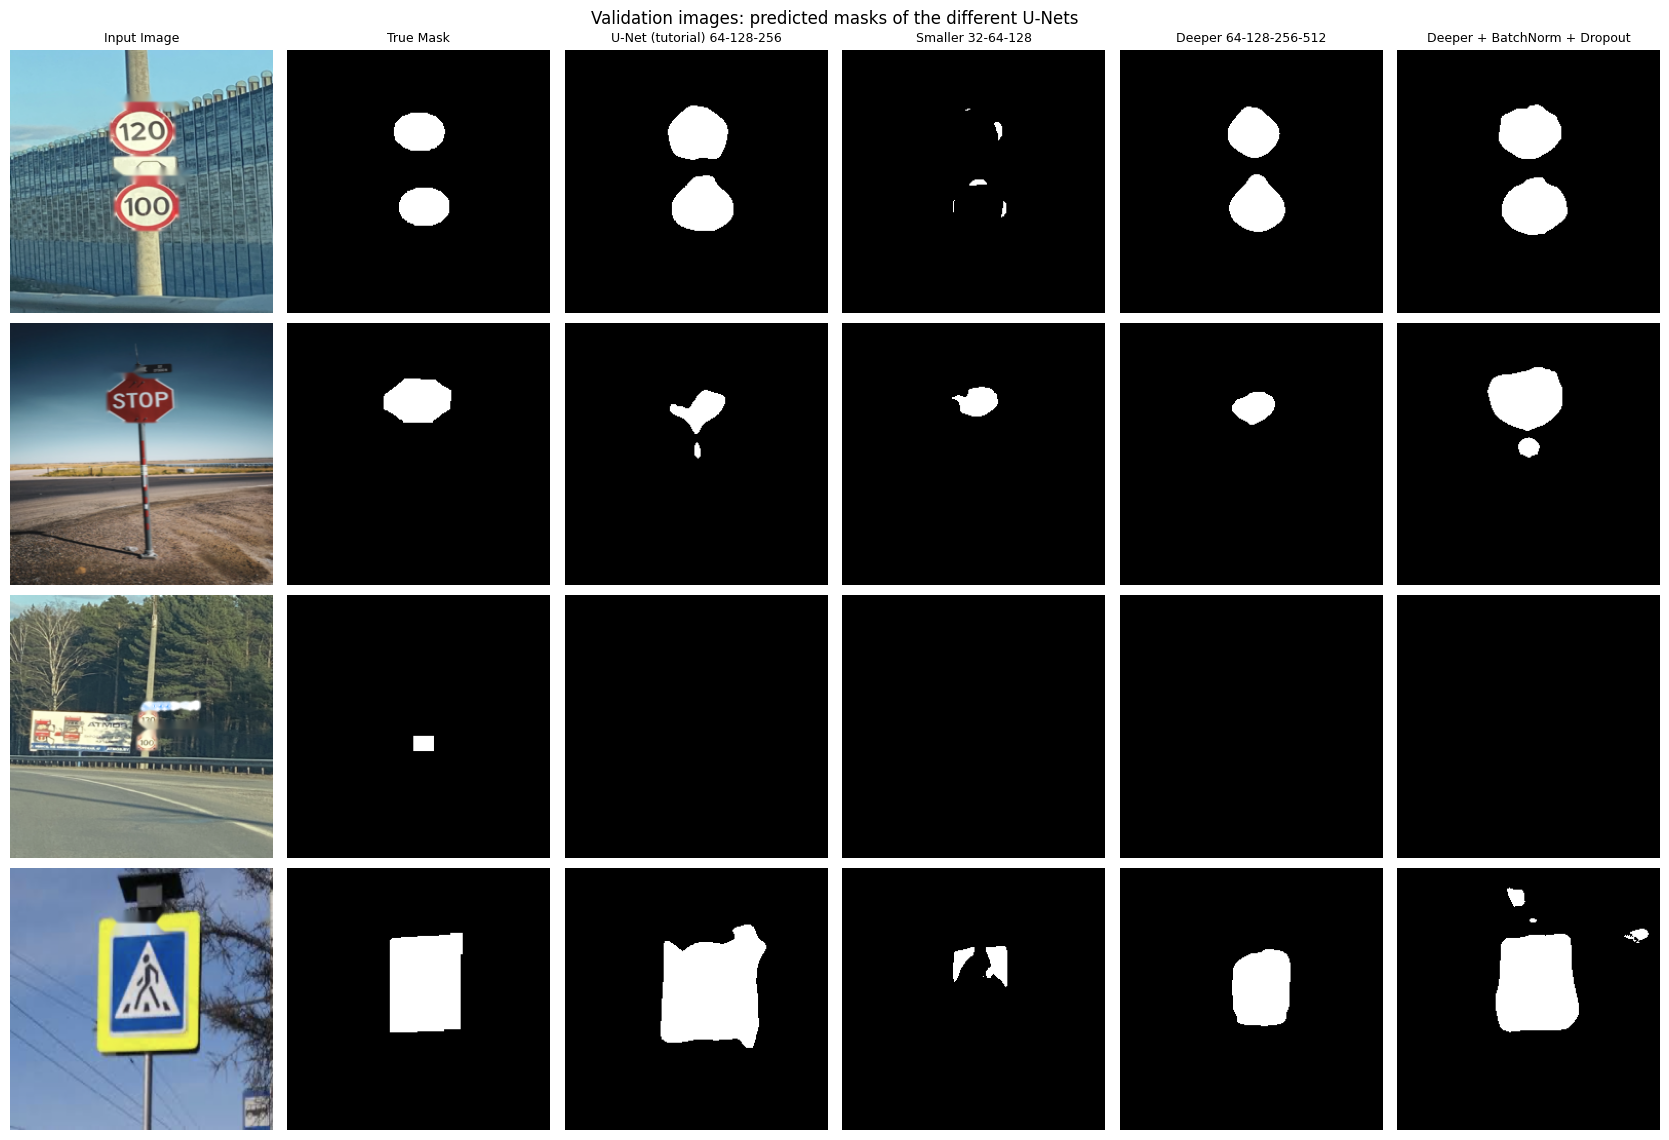

In [11]:
plt.figure(figsize=(14, 4.5))
for k, key in enumerate(['loss', 'val_loss', 'val_iou']):
    plt.subplot(1, 3, k + 1)
    for name in variants:
        plt.plot(range(1, EPOCHS + 1), seg_histories[name][key], label=name)
    plt.title({'loss': 'Training loss', 'val_loss': 'Validation loss', 'val_iou': 'Validation IoU'}[key])
    plt.xlabel('Epoch')
    plt.grid()
    if key != 'val_iou':
        plt.yscale('log')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


def compare_predictions(names, title, n=4):
    preds = {name: predict(seg_models[name], val_x) for name in names}
    picks = [i for i in range(len(val_x)) if val_y[i].sum() > 0][:n]
    cols = 2 + len(names)
    plt.figure(figsize=(2.8 * cols, 2.9 * len(picks)))
    for r, i in enumerate(picks):
        panels = [(val_x[i].permute(1, 2, 0), 'Input Image'), (val_y[i, 0], 'True Mask')]
        panels += [((preds[name][i, 0] > 0.5).float(), name) for name in names]
        for c, (img, label) in enumerate(panels):
            plt.subplot(len(picks), cols, r * cols + c + 1)
            plt.imshow(img, cmap=None if c == 0 else 'gray', vmin=0, vmax=1)
            if r == 0:
                plt.title(label, fontsize=9)
            plt.axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


compare_predictions(list(variants), 'Validation images: predicted masks of the different U-Nets')

## Block 12: Task 3 - Train with different learning rates

In [12]:
learning_rates = [1e-2, 1e-3, 1e-4, 1e-5]
lr_names = {}
for lr in learning_rates:
    if lr == 1e-4:
        # identical to the tutorial U-Net run in Task 2 (same seed, model and settings), so it is reused
        lr_names[lr] = 'U-Net (tutorial) 64-128-256'
    else:
        lr_names[lr] = f'U-Net (tutorial), lr={lr:g}'
        run(lr_names[lr], lambda: UNet((64, 128, 256)), lr=lr)

print(f"\n{'Learning rate':>13} {'Accuracy':>9} {'IoU':>7} {'Dice':>7} {'Best IoU':>9} {'Final train loss':>17}")
for lr in learning_rates:
    r, h = seg_results[lr_names[lr]], seg_histories[lr_names[lr]]
    print(f"{lr:13g} {r['accuracy']:9.4f} {r['iou']:7.4f} {r['dice']:7.4f} {r['best_iou']:9.4f} {h['loss'][-1]:17.4f}")


Training: U-Net (tutorial), lr=0.01 (1,883,137 parameters, lr=0.01)
Epoch 1/40 - loss: 232.8618 - accuracy: 0.7206 - val_loss: 0.2801 - val_accuracy: 0.9744 - val_iou: 0.0000
Epoch 10/40 - loss: 0.1377 - accuracy: 0.9689 - val_loss: 0.1185 - val_accuracy: 0.9744 - val_iou: 0.0000
Epoch 20/40 - loss: 0.1349 - accuracy: 0.9689 - val_loss: 0.1125 - val_accuracy: 0.9744 - val_iou: 0.0000
Epoch 30/40 - loss: 0.1276 - accuracy: 0.9689 - val_loss: 0.1088 - val_accuracy: 0.9744 - val_iou: 0.0000
Epoch 40/40 - loss: 0.1246 - accuracy: 0.9689 - val_loss: 0.1062 - val_accuracy: 0.9744 - val_iou: 0.0000

Training: U-Net (tutorial), lr=0.001 (1,883,137 parameters, lr=0.001)
Epoch 1/40 - loss: 0.3237 - accuracy: 0.8953 - val_loss: 0.1378 - val_accuracy: 0.9744 - val_iou: 0.0000
Epoch 10/40 - loss: 0.1081 - accuracy: 0.9689 - val_loss: 0.0869 - val_accuracy: 0.9744 - val_iou: 0.0000
Epoch 20/40 - loss: 0.0985 - accuracy: 0.9713 - val_loss: 0.0807 - val_accuracy: 0.9762 - val_iou: 0.0721
Epoch 30/40 

## Block 13: Task 3 - Visualize the results of the different learning rates

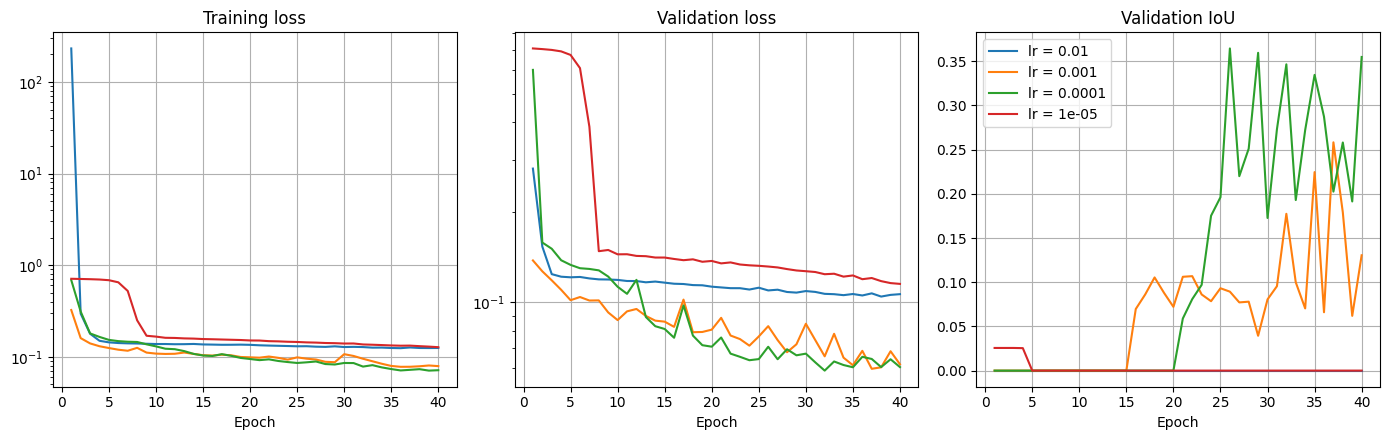

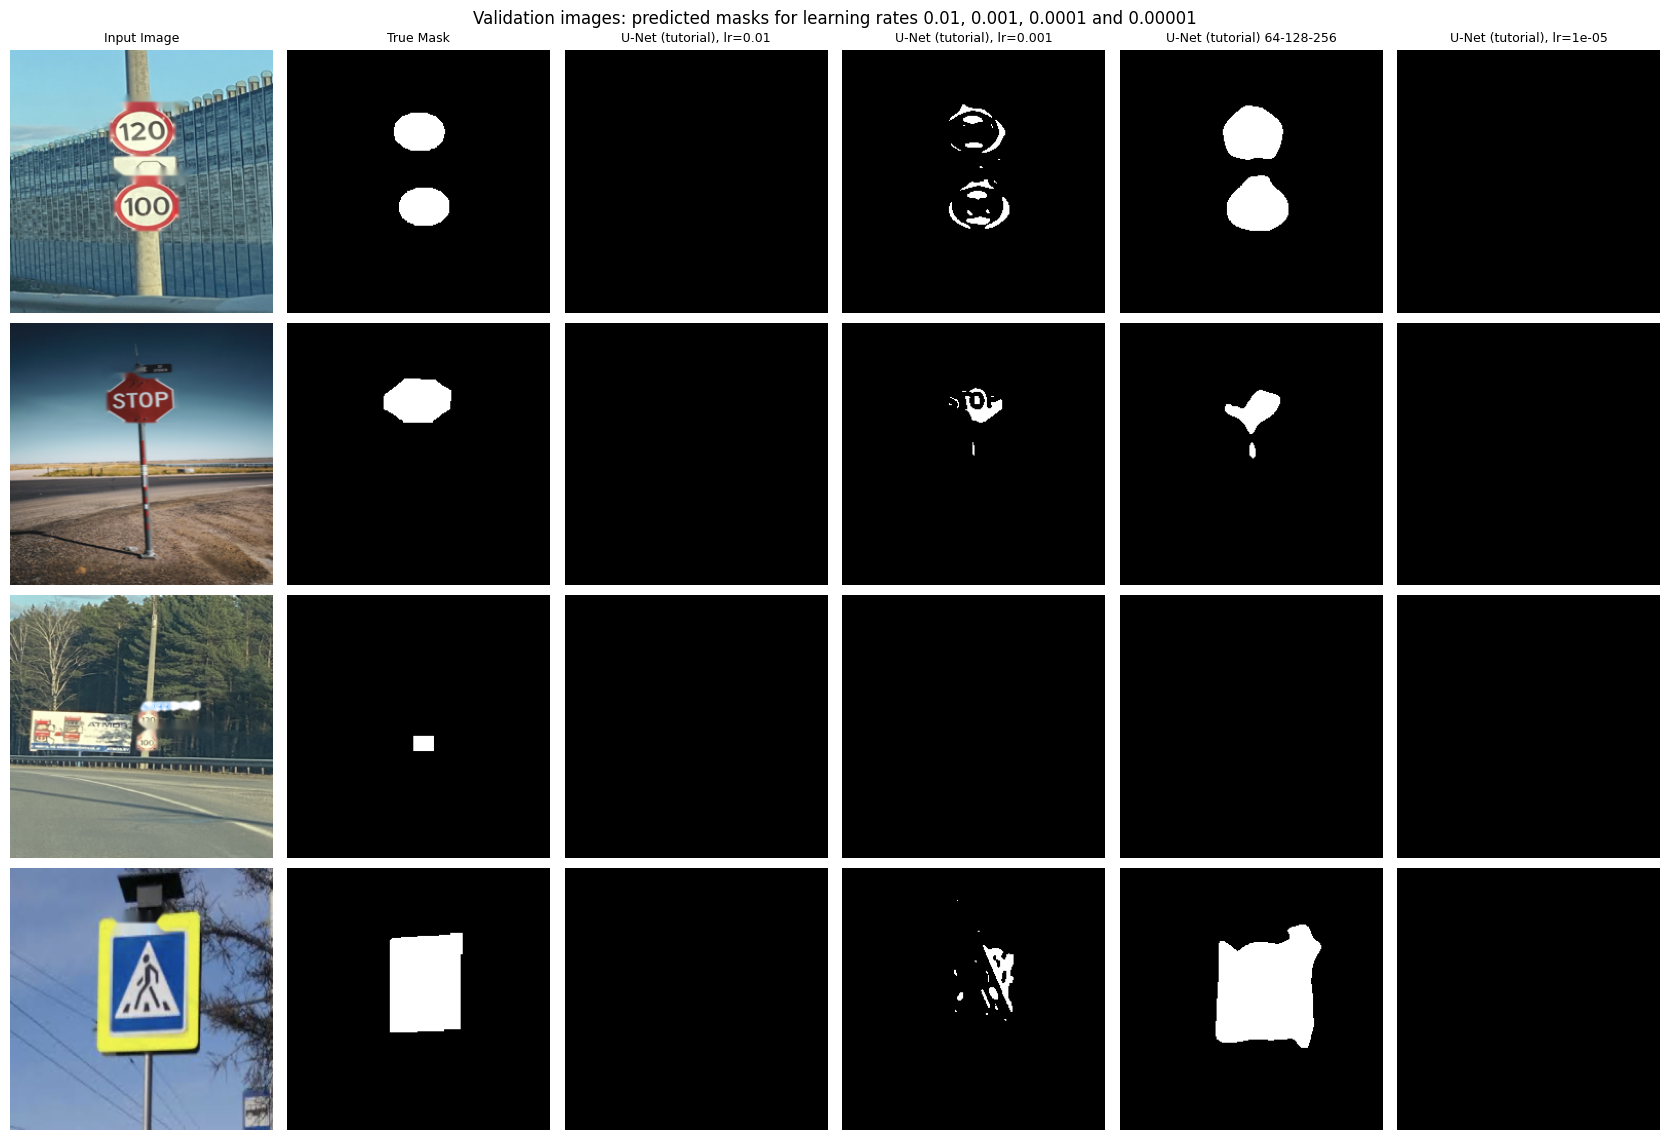

In [13]:
plt.figure(figsize=(14, 4.5))
for k, key in enumerate(['loss', 'val_loss', 'val_iou']):
    plt.subplot(1, 3, k + 1)
    for lr in learning_rates:
        plt.plot(range(1, EPOCHS + 1), seg_histories[lr_names[lr]][key], label=f'lr = {lr:g}')
    plt.title({'loss': 'Training loss', 'val_loss': 'Validation loss', 'val_iou': 'Validation IoU'}[key])
    plt.xlabel('Epoch')
    plt.grid()
    if key != 'val_iou':
        plt.yscale('log')
plt.legend()
plt.tight_layout()
plt.show()

compare_predictions([lr_names[lr] for lr in learning_rates],
                    'Validation images: predicted masks for learning rates 0.01, 0.001, 0.0001 and 0.00001')

## Block 14: Summary of all models

Model                             Parameters      LR  Accuracy     IoU    Dice  Time (s)
U-Net (tutorial) 64-128-256        1,883,137  0.0001    0.9786  0.3548  0.5237     223.0
Smaller 32-64-128                    471,553  0.0001    0.9730  0.1210  0.2158      90.8
Deeper 64-128-256-512              7,782,913  0.0001    0.9776  0.3066  0.4693     316.2
Deeper + BatchNorm + Dropout       7,788,545  0.0001    0.9724  0.4180  0.5896     355.0
U-Net (tutorial), lr=0.01          1,883,137    0.01    0.9744  0.0000  0.0000     219.0
U-Net (tutorial), lr=0.001         1,883,137   0.001    0.9738  0.1305  0.2308     237.7
U-Net (tutorial), lr=1e-05         1,883,137   1e-05    0.9744  0.0000  0.0000     249.0


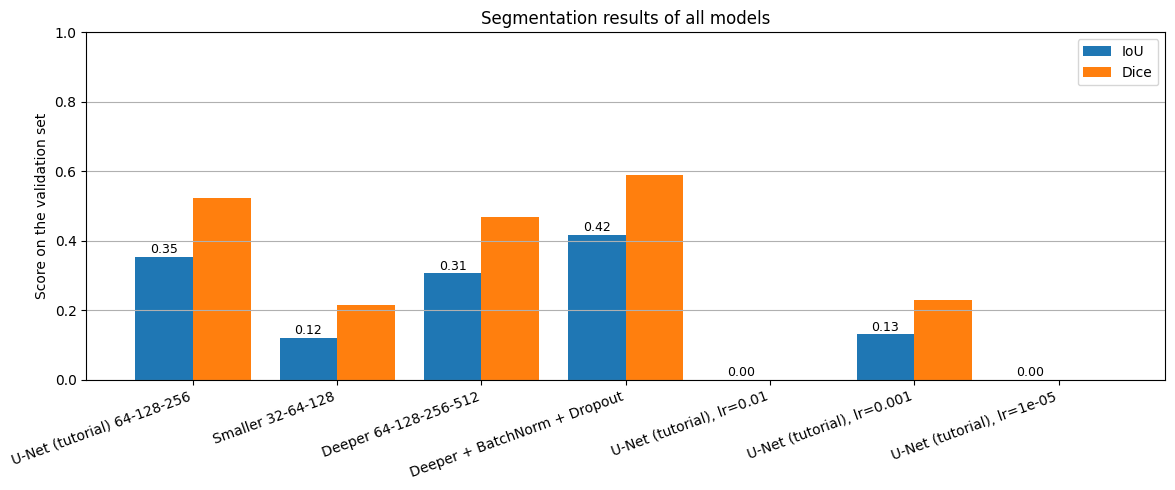

In [14]:
print(f"{'Model':32} {'Parameters':>11} {'LR':>7} {'Accuracy':>9} {'IoU':>7} {'Dice':>7} {'Time (s)':>9}")
for name, r in seg_results.items():
    print(f"{name:32} {r['params']:11,} {r['lr']:7g} {r['accuracy']:9.4f} {r['iou']:7.4f} {r['dice']:7.4f} {r['time']:9.1f}")

names = list(seg_results)
x = np.arange(len(names))
plt.figure(figsize=(12, 5))
plt.bar(x - 0.2, [seg_results[n]['iou'] for n in names], width=0.4, label='IoU')
plt.bar(x + 0.2, [seg_results[n]['dice'] for n in names], width=0.4, label='Dice')
for i, n in enumerate(names):
    plt.text(i - 0.2, seg_results[n]['iou'] + 0.01, f"{seg_results[n]['iou']:.2f}", ha='center', fontsize=9)
plt.xticks(x, names, rotation=20, ha='right')
plt.ylim(0, 1)
plt.ylabel('Score on the validation set')
plt.title('Segmentation results of all models')
plt.legend()
plt.grid(axis='y')
plt.tight_layout()
plt.show()